# Compaction under hydrostatic compression

Compare a single 3D element under equal compressive face loads. 

The cap model uses the Colorado Concrete parameters from Hofstetter, Simo and Taylor, Table 1, **present study**, with the nonassociative hardening law. 


This is hydrostatic (isotropic) compression: all three principal stresses are equal. 
It is not the usual drained triaxial compression test, in which an axial deviatoric stress is added to confinement.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import xara
from xara.units import create_units

units = create_units(system="mks")

In [2]:
#<hide>
if "thesis" in plt.style.available:
    plt.style.use("thesis")


## Common parameters

Cam Clay is chosen to match the cap pressure, zero-pressure shear intercept, and initial bulk tangent. Prevost's outer cone matches the cap envelope's zero-pressure shear intercept and its high-pressure linear slope; its first surface is smaller.

In [ ]:
# Colorado Concrete: Hofstetter et al., Table 1, present study.
Kref = 2100.0 * units.ksi
Gref = 1700.0 * units.ksi
density = 0.0
X0 = 16.0 * units.ksi
D = 0.0032 / units.ksi
W = 0.42
R = 2.89

gamma_cap = 1.80 * units.ksi  # paper's lambda; parser uses gamma
beta_cap = 0.54 / units.ksi
alpha_cap = 4.34 * units.ksi
theta_cap = 0.33
T_cap = -0.30 * units.ksi
Pc = X0 / 3.0

# The cap failure envelope has ||s|| = alpha - gamma at I1 = 0.
Fy_ref = np.sqrt(3/2) * (alpha_cap - gamma_cap)

# Cam Clay: match Pc and Fy; choose its remaining parameters for this
# illustration. Its particle bulk modulus is adjusted so its initial
# nonlinear elastic tangent equals Kref.
c_cc = 50.0 * units.ksi
e0_cc = 0.6
lambda_cc = 0.01
kappa_cc = 0.0
pi0_cc = Pc
M_cc = Fy_ref / np.sqrt(c_cc*pi0_cc)
beta_cc = lambda_cc / (1.0 + e0_cc)
K_cc = 1.0 / (1.0/Kref - beta_cc/c_cc)

# Prevost's outer cone matches the cap's asymptotic linear slope and
# zero-pressure intercept. Surface generation is automatic.
M_prevost = 3.0 * np.sqrt(3/2) * theta_cap
phi = np.degrees(np.arcsin(3*M_prevost/(6 + M_prevost)))
phase_angle = phi/2.0
cohesion_prevost = Fy_ref/2.0
p_ref = Pc
p_exp = 0.0
n_surfaces = 20
peak_shear_strain = 1.1*np.sqrt(2)/3 * (Fy_ref + M_prevost*p_ref)/Gref

pressure_history = np.linspace(0.0, 10.0*units.ksi, 201)


## Loading test

`CompactionTest.run(material, label, unload=False)` builds a unit cube with one `SSPbrick`. The three coordinate planes are symmetry planes; the other three faces carry equal compressive pressures, distributed to their corner nodes. `LoadControl` ramps the pressure through `pressure_history`. Set `unload=True` to follow the same pressure steps back down to zero.

The optional `configure(model, material_tag, element_tag)` callback runs after the element is created and before analysis, so a later test can update the material stage or parameters.

In [4]:
from xara.examples.material import CompactionTest

In [5]:
compaction_test = CompactionTest(pressure_history)

## Test 1 — Hydrostatic compression

The cap has a finite hydrostatic yield pressure. The Prevost cones remain open along the compressive hydrostatic axis; with pressure-dependent elasticity and the optional volumetric stiffness modification disabled, their response stays linear on this path. Cam Clay's parameters below are only a simple comparison, not a fit to the concrete data.

The dashed curve is the paper's nonassociative cap-hardening equation evaluated for this hydrostatic path, with the table's parameters:
$$
\varepsilon_c=\frac{p}{K}+
\begin{cases}
0, & 3p\le X_0,\\
W\left(e^{-D X_0}-e^{-3Dp}\right), & 3p>X_0.
\end{cases}
$$

In [6]:
material_models = {
    "CamClayPlastic": xara.MultiaxialMaterial(
        "CamClayPlastic", G=Gref, K=K_cc, c=c_cc, M=M_cc,
        pi0=pi0_cc, e0=e0_cc, clamda=lambda_cc, ckappa=kappa_cc,
        YFtol=1e-6, maxIter=100,
    ),
    "DruckerPlasticity02": xara.MultiaxialMaterial(
        "DruckerPlasticity02", G=Gref, K=Kref, Xo=X0, D=D, W=W, R=R,
        gamma=gamma_cap, theta=theta_cap, beta=beta_cap,
        alpha=alpha_cap, T=T_cap, tol=1e-7,
    ),
    "DruckerPrager01": xara.MultiaxialMaterial(
        "DruckerPrager01", G=Gref, K=Kref,
        Fy=Fy_ref,
        Fsat=0,
        Fo=0,
        alpha=theta_cap,
        alphap=theta_cap,    
    ),
    "PrevostMultiYield01": xara.MultiaxialMaterial(
        "PrevostMultiYield01", 3, density, Gref, Kref, phi,
        peak_shear_strain, p_ref, p_exp, phase_angle,
        0.0, 0.0, 0.0,  # contraction and dilation
        0.0, 0.0, 0.0,  # liquefaction
        n_surfaces, e0_cc, 0.9, 0.02, 0.7, units.atm,
        cohesion_prevost, 0.0, 1.0,  # Hv = 0; Pv inactive
    ),
    "LeeFenves": xara.MultiaxialMaterial(
        "LeeFenves", G=Gref, K=Kref,
        Fc=Fy_ref,
        Ft=Fy_ref,
        aC=1,
        Lc=1,
        Lt=1,
        Gc=1e6,
        Gt=1e6,
        alpha=theta_cap,
        alphap=theta_cap
    )
}


## Results

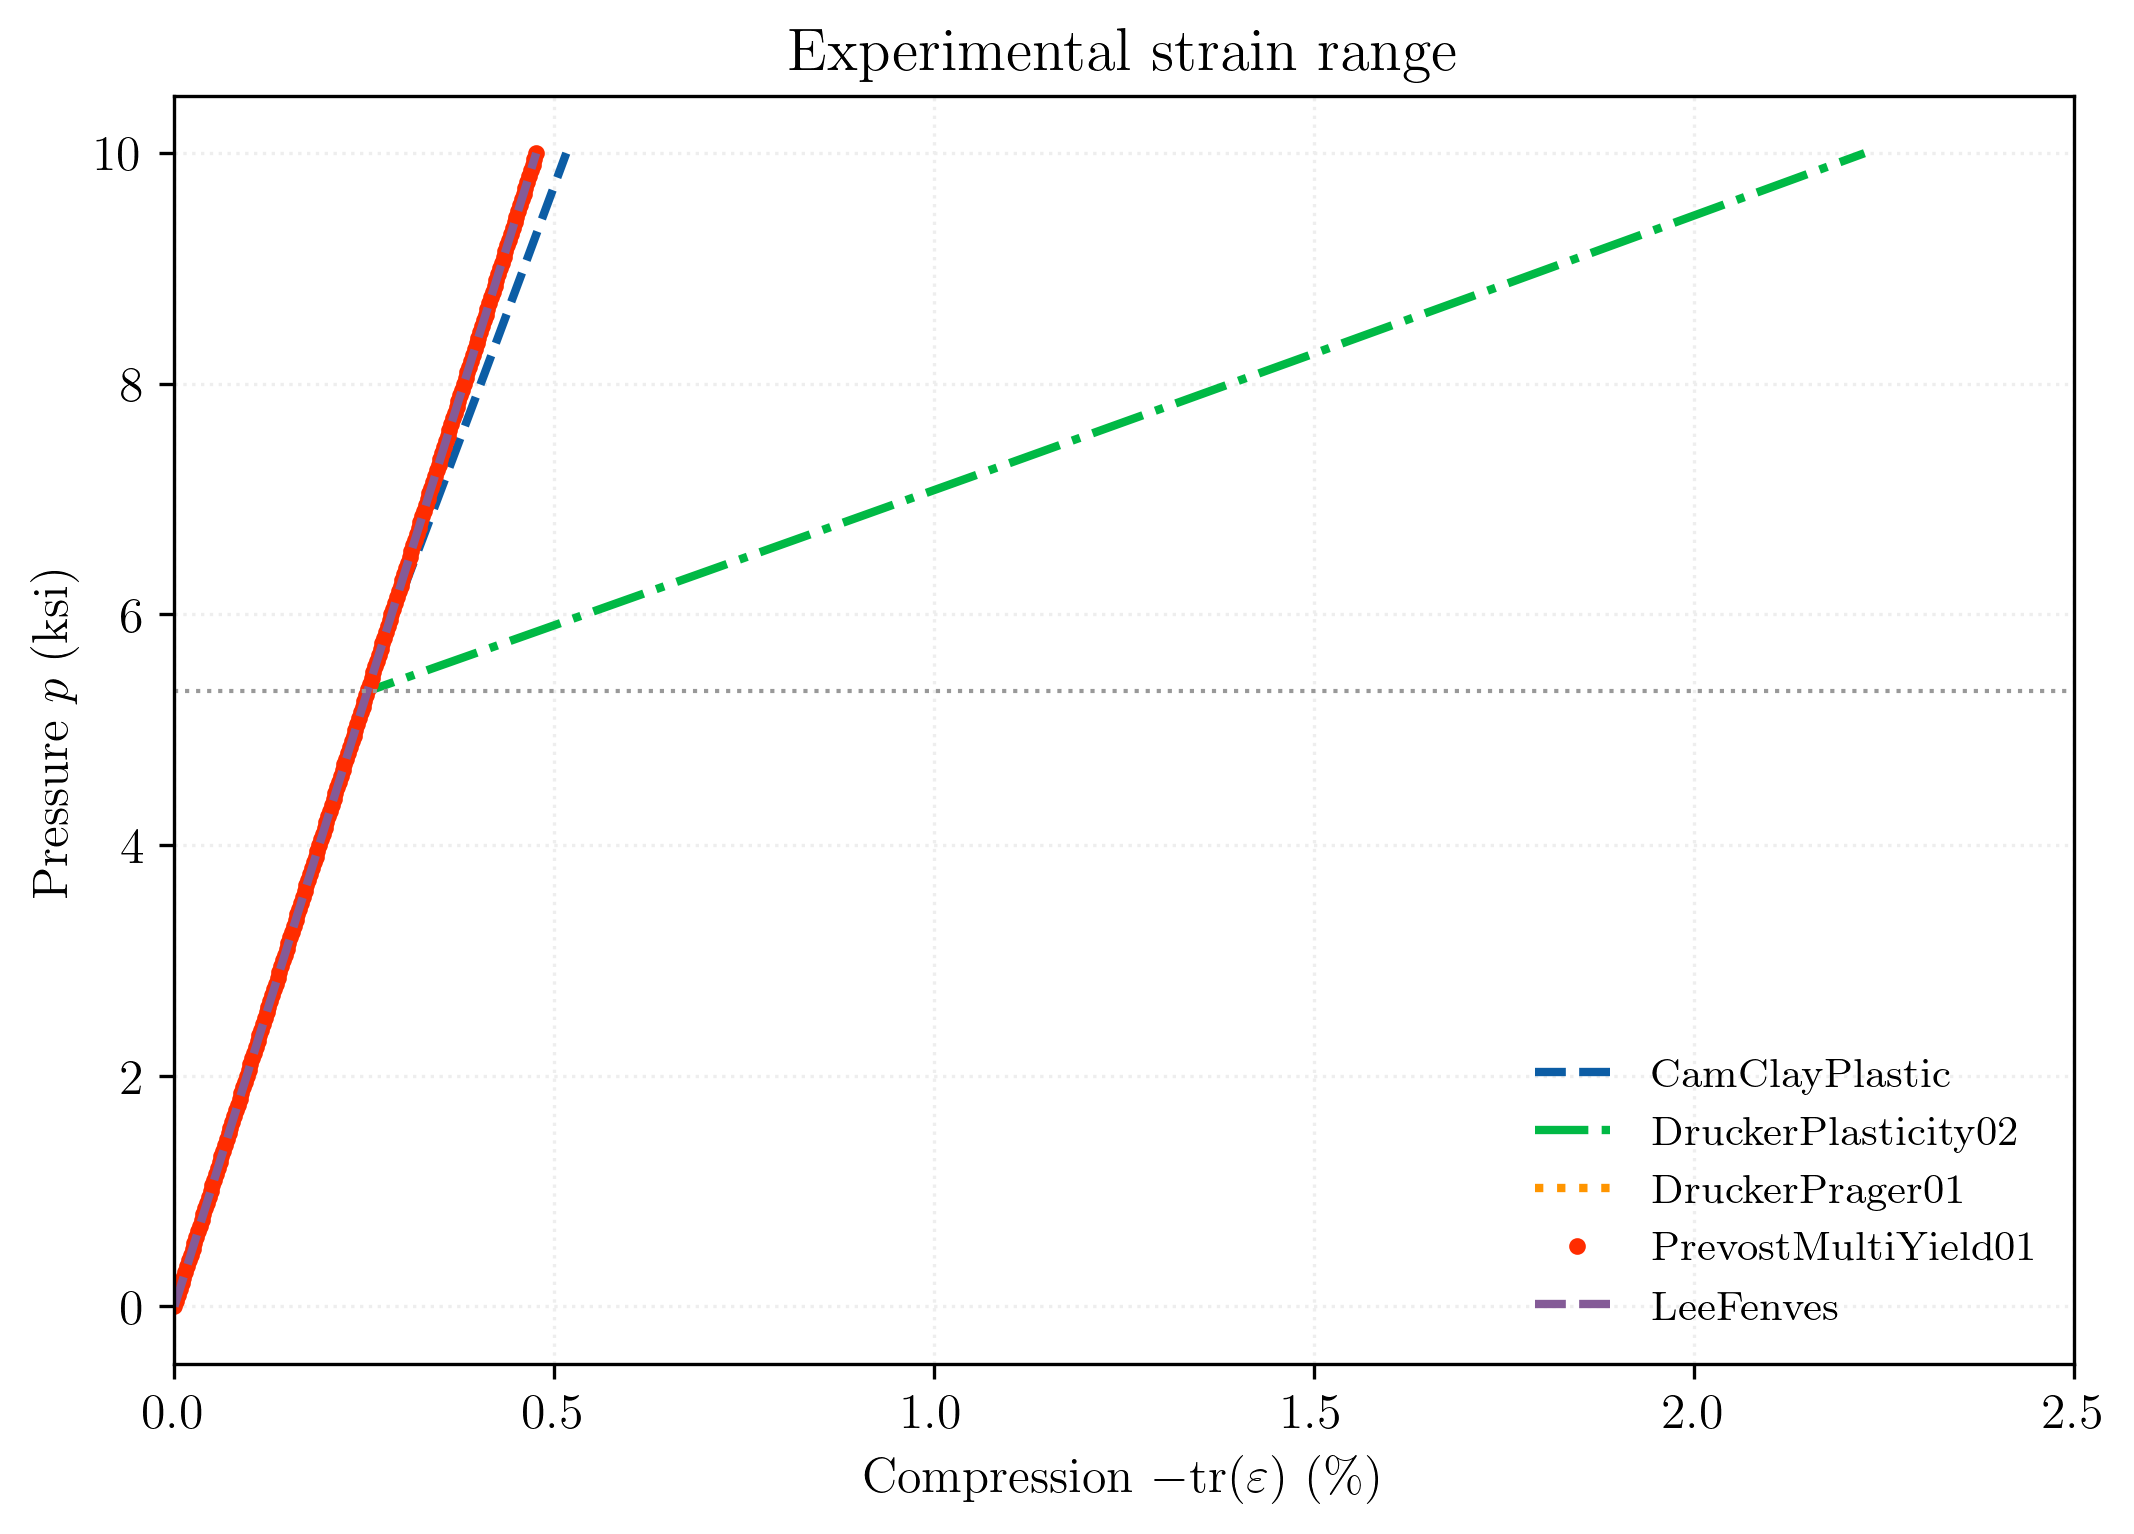

In [7]:
def plot_compaction_tests(results):
    lines = iter(['--', '-.', ':', "."]*10)
    fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
    for label, result in results.items():
        ax.plot(100*result.compression,
                result.p/units.ksi, next(lines),
                lw=2, label=label)


    ax.axhline(X0/3/units.ksi, color='0.6', lw=1, ls=':')
    ax.set_xlabel(r"Compression $-\mathrm{tr}(\varepsilon)$ (\%)")
    ax.set_ylabel(r"Pressure $p$ (ksi)")
    ax.set_title("Experimental strain range")
    ax.set_xlim(0, 2.5)
    # ax.grid(alpha=0.2)
    ax.legend(fontsize="small")
    return fig, ax



compaction_results = {
    label: compaction_test.run(material, label)
    for label, material in material_models.items()
}

fig, ax = plot_compaction_tests(compaction_results)